# Flight Booking Decision Assistant — completed experiment

This Notebook implements the existing proposal using hypothetical fares, not real airfare data. Maximizing the negative purchase reward minimizes cost. Run cells in order with the **Python (CS664 Flight Booking)** kernel.

The core includes simulation, tabular Q-learning, a fair four-strategy comparison, and a complete decision trace. Exact MDP references, a policy heatmap, and paired confidence intervals follow the core evaluation. The original proposal remains unchanged. The instructor PDF supplies the official submission requirements; the proposal is our implementation plan.

## 1. Setup and fixed experiment settings
**Purpose:** make the official experiment reproducible. States are `(time remaining, price)`; table columns represent BOOK and WAIT. Training and test randomness are independent.

In [1]:
# 1A — imports and official settings
from pathlib import Path
import csv
import json
import sys
import numpy as np
from IPython.display import display, Markdown

PRICES = np.array([120, 180, 240, 300, 360], dtype=int)
BOOK, WAIT = 0, 1
ACTION_NAMES = {BOOK: "BOOK", WAIT: "WAIT"}
TRAIN_EPISODES, TEST_TRAJECTORIES = 50_000, 10_000
ALPHA, GAMMA = 0.1, 1.0
TRAIN_SEED, TEST_SEED = 66401, 66402
OFFICIAL_THRESHOLD = 180
assert TRAIN_SEED != TEST_SEED
print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Training/test seeds:", TRAIN_SEED, TEST_SEED)

Python: /Users/sheungwanwong/Documents/bu.met.mssd/fall1.2026/metcs664/CS664_Project_Wong_Sheung_Wan/.venv/bin/python
NumPy: 2.5.4
Training/test seeds: 66401 66402


In [2]:
# 1B — artifact helpers and recorded assumptions
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

def save_csv(filename, rows):
    with (RESULTS / filename).open('w', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), lineterminator='\n')
        writer.writeheader()
        writer.writerows(rows)

assumptions = {
    'purchase_opportunities': 7, 'time_remaining': [6, 5, 4, 3, 2, 1, 0],
    'price_levels': PRICES.tolist(), 'initial_price': 'uniform over five levels',
    'wait_moves': [60, 0, -60], 'early_wait_times': [6, 5, 4, 3],
    'early_probabilities': [0.3, 0.3, 0.4], 'late_wait_times': [2, 1],
    'late_probabilities': [0.6, 0.2, 0.2], 'boundaries': 'clip to $120–$360',
    'book_reward': 'negative current price; terminate', 'wait_reward': 0,
    'deadline': 'BOOK mandatory at time 0',
    'excluded_events': ['refunds', 'cancellations', 'sold-out events'],
    'data_status': 'hypothetical probabilities; no measured airfare data',
}
(RESULTS / 'simulation_assumptions.json').write_text(json.dumps(assumptions, indent=2) + '\n')
verification_records = []

save_csv('training_parameters.csv', [
    {'parameter': name, 'value': value} for name, value in {
        'training_episodes': TRAIN_EPISODES, 'test_trajectories': TEST_TRAJECTORIES,
        'learning_rate': ALPHA, 'gamma': GAMMA, 'training_seed': TRAIN_SEED,
        'test_seed': TEST_SEED, 'epsilon_start': 1.0, 'epsilon_end': 0.05,
        'epsilon_decay_episodes': 40_000, 'evaluation_epsilon': 0,
        'official_threshold': OFFICIAL_THRESHOLD}.items()])

## 2. Price simulator
**Purpose:** encode exactly seven opportunities, time 6 through 0. The probabilities depend on the time **before** WAIT. An attempted move past a boundary stays at that boundary. At time 0, any requested action becomes BOOK. After booking, further steps raise an error.

Only the environment knows the transition probabilities. The learner below receives states and observed rewards.

In [3]:
# 2A — one price transition
def next_price(time_remaining, price, rng):
    if time_remaining not in range(1, 7) or price not in PRICES:
        raise ValueError("WAIT requires time 1–6 and a valid price")
    probabilities = (0.3, 0.3, 0.4) if time_remaining >= 3 else (0.6, 0.2, 0.2)
    change = int(rng.choice([60, 0, -60], p=probabilities))
    return int(np.clip(price + change, PRICES[0], PRICES[-1]))

In [4]:
# 2B — episode and terminal rules
class FlightBookingEnv:
    def __init__(self, rng):
        self.rng = rng
        self.state = None
        self.done = True

    def reset(self):
        self.state = (6, int(self.rng.choice(PRICES)))
        self.done = False
        return self.state

    def step(self, action):
        if self.done:
            raise RuntimeError("Reset before acting; a purchase ends the episode")
        if action not in (BOOK, WAIT):
            raise ValueError("Action must be BOOK or WAIT")
        time_remaining, price = self.state
        effective_action = BOOK if time_remaining == 0 else action
        if effective_action == BOOK:
            self.done = True
            return None, -price, True, effective_action
        self.state = (time_remaining - 1, next_price(time_remaining, price, self.rng))
        return self.state, 0, False, effective_action

### 2C. Verify the simulator before training
Controlled random choices check every price, every transition day, and all three possible moves, including the boundary stays. Additional episodes check rewards, mandatory deadline booking, and rejection of actions after purchase.

In [5]:
# 2C — exact transition checks
class ControlledRNG:
    def __init__(self, move):
        self.move = move
        self.seen_probabilities = None

    def choice(self, values, p=None):
        if p is None:
            return 240
        self.seen_probabilities = p
        return self.move

transition_checks = 0
for time_remaining in range(1, 7):
    for price in PRICES:
        for move in (60, 0, -60):
            rng = ControlledRNG(move)
            observed = next_price(time_remaining, int(price), rng)
            expected = min(360, max(120, int(price) + move))
            assert observed == expected
            assert rng.seen_probabilities == ((0.3, 0.3, 0.4) if time_remaining >= 3 else (0.6, 0.2, 0.2))
            transition_checks += 1
verification_records.append({'check': 'simulator transitions', 'cases': transition_checks, 'status': 'PASS', 'detail': 'all time/price/move combinations; probability regimes; both boundaries'})


In [6]:
# 2D — rewards, deadline, and termination checks
for purchase_day in range(7):
    env = FlightBookingEnv(np.random.default_rng(100 + purchase_day))
    state = env.reset()
    assert state[0] == 6 and state[1] in PRICES
    for day in range(purchase_day):
        previous = state
        state, reward, done, action = env.step(WAIT)
        assert state[0] == previous[0] - 1 and state[1] in PRICES
        assert reward == 0 and not done and action == WAIT
    price_at_purchase = state[1]
    # Deliberately request WAIT at the deadline to verify forced booking.
    terminal, reward, done, action = env.step(WAIT if purchase_day == 6 else BOOK)
    assert terminal is None and done and action == BOOK
    assert reward == -price_at_purchase
    try:
        env.step(WAIT)
    except RuntimeError:
        pass
    else:
        raise AssertionError("Acting after purchase must fail")
print(f"PASS: {transition_checks} exact transitions; all 7 purchase days; rewards; deadline BOOK; post-purchase rejection.")
verification_records.append({'check': 'episode rules', 'cases': 7, 'status': 'PASS', 'detail': 'all purchase days; BOOK/WAIT rewards; deadline; reject post-purchase action'})


PASS: 90 exact transitions; all 7 purchase days; rewards; deadline BOOK; post-purchase rejection.


## 3. Tabular Q-learning
**Purpose:** learn the cost of BOOK and WAIT from experience. The table has 7 time rows × 5 price rows × 2 actions. At the deadline only BOOK is legal. Greedy ties choose BOOK, making predictions deterministic.

`Q ← old + α × (target − old)`. The target is reward alone for a terminal purchase; otherwise it is reward plus γ times the best legal next-state value. With γ = 1, WAIT includes the undiscounted eventual purchase cost.

In [7]:
# 3A — indexing, exploration, and greedy prediction
PRICE_INDEX = {int(price): i for i, price in enumerate(PRICES)}

def best_action(q, state):
    time_remaining, price = state
    if time_remaining == 0:
        return BOOK
    return int(np.argmax(q[time_remaining, PRICE_INDEX[price]]))

def epsilon_for(episode_index):
    fraction = min(episode_index / 39_999, 1.0)
    return 1.0 + (0.05 - 1.0) * fraction

def choose_training_action(q, state, rng, epsilon):
    if state[0] == 0:
        return BOOK
    if rng.random() < epsilon:
        return int(rng.integers(2))
    return best_action(q, state)

assert epsilon_for(0) == 1.0
assert np.isclose(epsilon_for(39_999), 0.05)
assert np.isclose(epsilon_for(49_999), 0.05)

In [8]:
# 3B — one real Q-value update
def update_q(q, state, action, reward, next_state, done, alpha, gamma):
    row = (state[0], PRICE_INDEX[state[1]], action)
    old = float(q[row])
    if done:
        target = float(reward)  # No bootstrap after a purchase.
    else:
        next_action = best_action(q, next_state)
        target = reward + gamma * q[next_state[0], PRICE_INDEX[next_state[1]], next_action]
    q[row] = old + alpha * (target - old)
    return {"state": state, "action": ACTION_NAMES[action], "old": old,
            "reward": reward, "target": float(target), "learning_rate": alpha,
            "updated": float(q[row]), "terminal": done}

# Isolated checks never change the official trained Q-table.
scratch = np.zeros((7, 5, 2))
scratch[0, PRICE_INDEX[240]] = [-240, 999]  # Illegal deadline WAIT must be ignored.
check = update_q(scratch, (1, 240), WAIT, 0, (0, 240), False, 0.1, 1.0)
assert check['target'] == -240 and check['updated'] == -24
check = update_q(scratch, (0, 240), BOOK, -240, None, True, 0.1, 1.0)
assert check['target'] == -240
print("PASS: legal-action bootstrap and terminal reward-only updates.")
verification_records.append({'check': 'Q-value updates', 'cases': 2, 'status': 'PASS', 'detail': 'legal next-action bootstrap; terminal reward-only target'})


PASS: legal-action bootstrap and terminal reward-only updates.


### 3C. Train 50,000 episodes
Epsilon decreases linearly from 1.0 on episode 1 to 0.05 on episode 40,000, then stays at 0.05. The learner never reads the probability table. Coverage counts show how often each legal state/action pair was updated; coverage alone does not prove convergence.

In [9]:
# 3C — training loop
def train_q_learning():
    rng = np.random.default_rng(TRAIN_SEED)
    env = FlightBookingEnv(rng)
    q = np.zeros((7, 5, 2), dtype=float)
    visits = np.zeros_like(q, dtype=int)
    episode_costs = np.empty(TRAIN_EPISODES, dtype=int)
    first_update = None
    wait_update = None
    for episode in range(TRAIN_EPISODES):
        state = env.reset()
        epsilon = epsilon_for(episode)
        while True:
            action = choose_training_action(q, state, rng, epsilon)
            next_state, reward, done, effective_action = env.step(action)
            record = update_q(q, state, effective_action, reward, next_state, done, ALPHA, GAMMA)
            visits[state[0], PRICE_INDEX[state[1]], effective_action] += 1
            if first_update is None:
                first_update = {"episode": episode + 1, **record}
            if wait_update is None and effective_action == WAIT and record['target'] < 0:
                wait_update = {"episode": episode + 1, **record}
            if done:
                episode_costs[episode] = -reward
                break
            state = next_state
    return q, visits, episode_costs, first_update, wait_update

Q, visit_counts, training_costs, first_update, wait_update = train_q_learning()
legal_visits = np.concatenate([visit_counts[0, :, BOOK], visit_counts[1:].ravel()])
assert np.all(legal_visits > 0) and np.all(np.isfinite(Q))
assert np.all(np.isin(training_costs, PRICES))
print(f"Trained {TRAIN_EPISODES:,} complete episodes; all {len(legal_visits)} legal state/action pairs visited.")
print(f"Minimum legal pair visits: {legal_visits.min()}; final epsilon: {epsilon_for(TRAIN_EPISODES - 1):.2f}")

Trained 50,000 complete episodes; all 65 legal state/action pairs visited.
Minimum legal pair visits: 22; final epsilon: 0.05


In [10]:
# 3D — display actual updates and BOOK/WAIT predictions
for label, record in (("First observed update", first_update), ("Observed WAIT update", wait_update)):
    assert record is not None
    print(f"{label}: episode {record['episode']}, state={record['state']}, action={record['action']}")
    print(f"  old={record['old']:.6f}, reward={record['reward']}, target={record['target']:.6f}, alpha={record['learning_rate']}")
    print(f"  updated = {record['old']:.6f} + {record['learning_rate']} * ({record['target']:.6f} - {record['old']:.6f}) = {record['updated']:.6f}")

def predict(time_remaining, current_price):
    if time_remaining not in range(7) or current_price not in PRICE_INDEX:
        raise ValueError("Use time 0–6 and one of the five price levels")
    return ACTION_NAMES[best_action(Q, (time_remaining, current_price))]

for state in ((6, 120), (6, 240), (2, 180), (0, 360)):
    print(f"Prediction for {state}: {predict(*state)}")
assert all(predict(0, int(p)) == "BOOK" for p in PRICES)

First observed update: episode 1, state=(6, 120), action=BOOK
  old=0.000000, reward=-120, target=-120.000000, alpha=0.1
  updated = 0.000000 + 0.1 * (-120.000000 - 0.000000) = -12.000000
Observed WAIT update: episode 376, state=(1, 240), action=WAIT
  old=0.000000, reward=0, target=-30.000000, alpha=0.1
  updated = 0.000000 + 0.1 * (-30.000000 - 0.000000) = -3.000000
Prediction for (6, 120): BOOK
Prediction for (6, 240): WAIT
Prediction for (2, 180): BOOK
Prediction for (0, 360): BOOK


## 4. Fair evaluation on 10,000 fresh trajectories
**Purpose:** compare all four policies on the same prices, removing differences caused by unrelated test samples. The simulator pre-generates seven potential prices per trajectory using a separate test seed. These are counterfactual future prices for the evaluator, not inputs to a strategy. Each policy receives **only `(time remaining, current price)`**, and the evaluator stops at purchase.

The Q-learning strategy is greedy: no epsilon, random action, updates, or retraining during evaluation. The official fixed threshold stays at $180.

In [11]:
# 4A — generate independent shared test trajectories
def generate_test_trajectories(count, seed):
    env = FlightBookingEnv(np.random.default_rng(seed))
    paths = np.empty((count, 7), dtype=int)
    for index in range(count):
        state = env.reset()
        paths[index, 0] = state[1]
        for day in range(1, 7):
            state, reward, done, action = env.step(WAIT)
            assert reward == 0 and not done
            paths[index, day] = state[1]
    paths.setflags(write=False)
    return paths

test_paths = generate_test_trajectories(TEST_TRAJECTORIES, TEST_SEED)
assert test_paths.shape == (10_000, 7)
assert np.all(np.isin(test_paths, PRICES))
print(f"Generated {len(test_paths):,} fresh seven-price trajectories with test seed {TEST_SEED}.")

Generated 10,000 fresh seven-price trajectories with test seed 66402.


In [12]:
# 4B — state-only policies
def immediate_policy(state):
    return BOOK

def threshold_policy(threshold):
    def policy(state):
        time_remaining, price = state
        return BOOK if time_remaining == 0 or price <= threshold else WAIT
    return policy

def learned_policy(state):
    return best_action(Q, state)  # Deterministic; reads no future prices.

In [13]:
# 4C — stop-on-purchase evaluator
def play_path(path, policy):
    trace = []
    for day in range(7):
        state = (6 - day, int(path[day]))
        requested_action = policy(state)
        if requested_action not in (BOOK, WAIT):
            raise ValueError("Policy returned an invalid action")
        action = BOOK if state[0] == 0 else requested_action
        reward = -state[1] if action == BOOK else 0
        trace.append({"day": day + 1, "state": state,
                      "action": ACTION_NAMES[action], "reward": reward})
        if action == BOOK:
            return state[1], trace
    raise AssertionError("Deadline booking must terminate the trajectory")

OFFICIAL_POLICIES = {
    "Immediate booking": immediate_policy,
    "Minimum-price rule ($120)": threshold_policy(120),
    "Fixed-threshold rule ($180)": threshold_policy(OFFICIAL_THRESHOLD),
    "Q-learning (greedy)": learned_policy,
}
assert OFFICIAL_THRESHOLD == 180

In [14]:
# 4D — evaluator checks
# Policy-call counts verify termination and state-only observations.
seen_states = []
def spy_policy(state):
    assert isinstance(state, tuple) and len(state) == 2
    seen_states.append(state)
    return threshold_policy(180)(state)
synthetic = [300, 240, 180, 120, 360, 360, 360]
cost, trace = play_path(synthetic, spy_policy)
assert cost == 180 and seen_states == [(6, 300), (5, 240), (4, 180)]
assert play_path(synthetic, immediate_policy)[0] == 300
assert play_path(synthetic, threshold_policy(120))[0] == 120
cost, trace = play_path([360] * 7, lambda state: WAIT)
assert cost == 360 and len(trace) == 7 and trace[-1]['action'] == 'BOOK'
print("PASS: current-state-only calls, all baseline rules, stop after purchase, forced deadline in evaluator.")

PASS: current-state-only calls, all baseline rules, stop after purchase, forced deadline in evaluator.


In [15]:
# 4E — official comparison and paired cost differences
q_before_evaluation = Q.copy()
official_costs = {
    name: np.array([play_path(path, policy)[0] for path in test_paths], dtype=int)
    for name, policy in OFFICIAL_POLICIES.items()
}
assert np.array_equal(Q, q_before_evaluation)
assert all(len(costs) == 10_000 and np.all(np.isin(costs, PRICES)) for costs in official_costs.values())
q_costs = official_costs['Q-learning (greedy)']
comparison = []
for name, costs in official_costs.items():
    comparison.append({"strategy": name, "trajectories": len(costs),
                       "mean_purchase_cost": float(costs.mean()),
                       "mean_paired_saving_vs_q": float((costs - q_costs).mean())})
table = "| Strategy | Test trajectories | Mean purchase cost | Mean paired saving from Q |\n|---|---:|---:|---:|\n"
for row in comparison:
    table += f"| {row['strategy']} | {row['trajectories']:,} | ${row['mean_purchase_cost']:.2f} | ${row['mean_paired_saving_vs_q']:.2f} |\n"
display(Markdown(table))
print("Positive saving = Q-learning costs less; negative saving = baseline costs less.")
print("PASS: evaluation made no changes to the trained Q-table; exploration disabled.")

| Strategy | Test trajectories | Mean purchase cost | Mean paired saving from Q |
|---|---:|---:|---:|
| Immediate booking | 10,000 | $239.58 | $24.73 |
| Minimum-price rule ($120) | 10,000 | $223.48 | $8.62 |
| Fixed-threshold rule ($180) | 10,000 | $219.74 | $4.88 |
| Q-learning (greedy) | 10,000 | $214.85 | $0.00 |


Positive saving = Q-learning costs less; negative saving = baseline costs less.
PASS: evaluation made no changes to the trained Q-table; exploration disabled.


## 5. One complete Q-learning decision trace
**Purpose:** connect current state → greedy action → observed reward → final purchase cost. For a readable example, choose the first test trajectory with at least three decisions. This selection is only for illustration, never for computing the comparison. Stop displaying at purchase; unseen future prices are not shown.

In [16]:
# 5A — actual states, actions, and final cost
trace_index = next(i for i, path in enumerate(test_paths)
                   if len(play_path(path, learned_policy)[1]) >= 3)
trace_cost, decision_trace = play_path(test_paths[trace_index], learned_policy)
trace_table = "| Day | State (time remaining, price) | Q(BOOK) | Q(WAIT) | Action | Reward |\n|---:|---|---:|---:|---|---:|\n"
for step in decision_trace:
    time_remaining, price = step['state']
    book_value, wait_value = Q[time_remaining, PRICE_INDEX[price]]
    wait_text = f"{wait_value:.3f}" if time_remaining > 0 else "illegal"
    trace_table += f"| {step['day']} | ({time_remaining}, ${price}) | {book_value:.3f} | {wait_text} | {step['action']} | {step['reward']} |\n"
display(Markdown(trace_table))
print(f"Test trajectory index (zero-based): {trace_index}")
print(f"Final purchase cost: ${trace_cost}; episode ended after {len(decision_trace)} decisions.")
assert decision_trace[-1]['action'] == 'BOOK'
assert all(step['action'] == 'WAIT' for step in decision_trace[:-1])
assert sum(step['reward'] for step in decision_trace) == -trace_cost

| Day | State (time remaining, price) | Q(BOOK) | Q(WAIT) | Action | Reward |
|---:|---|---:|---:|---|---:|
| 1 | (6, $360) | -360.000 | -293.377 | WAIT | 0 |
| 2 | (5, $300) | -300.000 | -273.533 | WAIT | 0 |
| 3 | (4, $360) | -360.000 | -312.530 | WAIT | 0 |
| 4 | (3, $360) | -360.000 | -326.366 | WAIT | 0 |
| 5 | (2, $360) | -360.000 | -335.198 | WAIT | 0 |
| 6 | (1, $360) | -360.000 | -348.515 | WAIT | 0 |
| 7 | (0, $360) | -360.000 | illegal | BOOK | -360 |


Test trajectory index (zero-based): 1
Final purchase cost: $360; episode ended after 7 decisions.


## 6. Exact finite-horizon MDP reference
**Purpose:** distinguish finite training error from test-sample noise. Work backward from the mandatory deadline. In cost units, `V*(0,p)=p` and `V*(t,p)=min(p, Σ P(p′|t,p)V*(t−1,p′))`. A fixed policy uses its chosen action instead of taking the minimum.

This analytical reference knows the hypothetical simulator probabilities. Training and the four evaluated policies are unchanged and never receive this table. “Exact” means full finite-horizon expectation, computed to floating-point precision, not a Monte Carlo estimate. Average over the five equally likely starting prices.

In [17]:
# 6A — analytical transition matrices
def transition_matrix(time_remaining):
    matrix = np.zeros((5, 5))
    for i, price in enumerate(PRICES):
        for move_index, move in enumerate((60, 0, -60)):
            rng = ControlledRNG(move)
            following = next_price(time_remaining, int(price), rng)
            matrix[i, PRICE_INDEX[following]] += rng.seen_probabilities[move_index]
    return matrix

TRANSITIONS = {t: transition_matrix(t) for t in range(1, 7)}
assert all(np.allclose(matrix.sum(axis=1), 1) for matrix in TRANSITIONS.values())
assert all(np.all(matrix >= 0) for matrix in TRANSITIONS.values())
assert np.allclose(TRANSITIONS[6][0], [0.7, 0.3, 0, 0, 0])
assert np.allclose(TRANSITIONS[1][-1], [0, 0, 0, 0.2, 0.8])

In [18]:
# 6B — backward induction and exact policy evaluation
def solve_optimal_mdp():
    values = np.zeros((7, 5))
    actions = np.full((7, 5), BOOK, dtype=int)
    values[0] = PRICES
    for t in range(1, 7):
        waiting_cost = TRANSITIONS[t] @ values[t - 1]
        # Resolve numerical ties as BOOK, consistent with the learner.
        actions[t] = np.where(waiting_cost < PRICES - 1e-10, WAIT, BOOK)
        values[t] = np.where(actions[t] == BOOK, PRICES, waiting_cost)
    return values, actions

def exact_policy_values(policy):
    values = np.zeros((7, 5))
    values[0] = PRICES
    for t in range(1, 7):
        waiting_cost = TRANSITIONS[t] @ values[t - 1]
        for i, price in enumerate(PRICES):
            values[t, i] = price if policy((t, int(price))) == BOOK else waiting_cost[i]
    return values

optimal_values, optimal_actions = solve_optimal_mdp()
exact_values = {name: exact_policy_values(policy) for name, policy in OFFICIAL_POLICIES.items()}
optimal_expected_cost = float(optimal_values[6].mean())
learned_expected_cost = float(exact_values['Q-learning (greedy)'][6].mean())
optimality_gap = learned_expected_cost - optimal_expected_cost
assert np.array_equal(Q, q_before_evaluation)

In [19]:
# 6C — independently verify exact expectations
from itertools import product

def enumerated_expected_cost(policy):
    total = 0.0
    # Enumerate all 5 × 3^6 latent-move paths; policies still see only current state.
    for start in PRICES:
        for moves in product((60, 0, -60), repeat=6):
            price, probability = int(start), 1 / 5
            path = [price]
            for t, move in zip(range(6, 0, -1), moves):
                probabilities = (0.3, 0.3, 0.4) if t >= 3 else (0.6, 0.2, 0.2)
                probability *= probabilities[(60, 0, -60).index(move)]
                price = min(360, max(120, price + move))
                path.append(price)
            total += probability * play_path(path, policy)[0]
    return total

optimal_policy = lambda state: int(optimal_actions[state[0], PRICE_INDEX[state[1]]])
assert np.all(optimal_actions[0] == BOOK)
assert np.allclose(optimal_values[0], PRICES)
assert all(np.all(values >= optimal_values - 1e-9) for values in exact_values.values())
for name, policy in {**OFFICIAL_POLICIES, 'Optimal MDP reference': optimal_policy}.items():
    expected = optimal_expected_cost if name == 'Optimal MDP reference' else exact_values[name][6].mean()
    assert np.isclose(enumerated_expected_cost(policy), expected, atol=1e-8, rtol=0)
assert np.isclose(exact_values['Immediate booking'][6].mean(), 240)
assert all(optimal_policy((0, int(price))) == BOOK for price in PRICES)
print('PASS: transition probabilities/boundaries, deadline, optimal dominance; five policies verified by 3,645-path enumeration each.')
verification_records.append({'check': 'exact MDP reference', 'cases': 5 * 3645, 'status': 'PASS', 'detail': 'five full latent-path expectations match backward induction; optimal dominates all policies'})


PASS: transition probabilities/boundaries, deadline, optimal dominance; five policies verified by 3,645-path enumeration each.


In [20]:
# 6D — save analytical comparison and per-state references
mdp_comparison = [{'policy': 'Optimal MDP reference', 'exact_expected_cost': optimal_expected_cost,
                   'gap_above_optimal': 0.0, 'value_type': 'analytical reference'}]
for name, values in exact_values.items():
    expected = float(values[6].mean())
    mdp_comparison.append({'policy': name, 'exact_expected_cost': expected,
                           'gap_above_optimal': expected - optimal_expected_cost,
                           'value_type': 'analytical reference'})
save_csv('exact_mdp_comparison.csv', mdp_comparison)
state_references = []
for t in range(6, -1, -1):
    for i, price in enumerate(PRICES):
        state_references.append({'time_remaining': t, 'price': int(price),
            'optimal_action': ACTION_NAMES[int(optimal_actions[t, i])],
            'learned_action': predict(t, int(price)),
            'optimal_expected_cost': float(optimal_values[t, i]),
            'learned_policy_expected_cost': float(exact_values['Q-learning (greedy)'][t, i])})
save_csv('exact_state_values.csv', state_references)
print(f'Analytical optimal expected cost: ${optimal_expected_cost:.6f}')
print(f'Analytical learned-policy expected cost: ${learned_expected_cost:.6f}')
print(f'Learned policy minus optimal: ${optimality_gap:.6f}')
display(Markdown('| Analytical reference | Expected cost |\n|---|---:|\n' +
    f'| Optimal MDP | ${optimal_expected_cost:.6f} |\n| Learned policy | ${learned_expected_cost:.6f} |\n' +
    f'| Gap above optimum | ${optimality_gap:.6f} |'))

Analytical optimal expected cost: $207.274224
Analytical learned-policy expected cost: $215.709120
Learned policy minus optimal: $8.434896


| Analytical reference | Expected cost |
|---|---:|
| Optimal MDP | $207.274224 |
| Learned policy | $215.709120 |
| Gap above optimum | $8.434896 |

## 7. BOOK/WAIT policy heatmap
**Purpose:** visualize the learned greedy action at all 35 states. Columns are current prices; rows are time remaining, ordered from the first opportunity down to the deadline. This is the learned policy, not the exact optimum. Every deadline cell is mandatory BOOK.

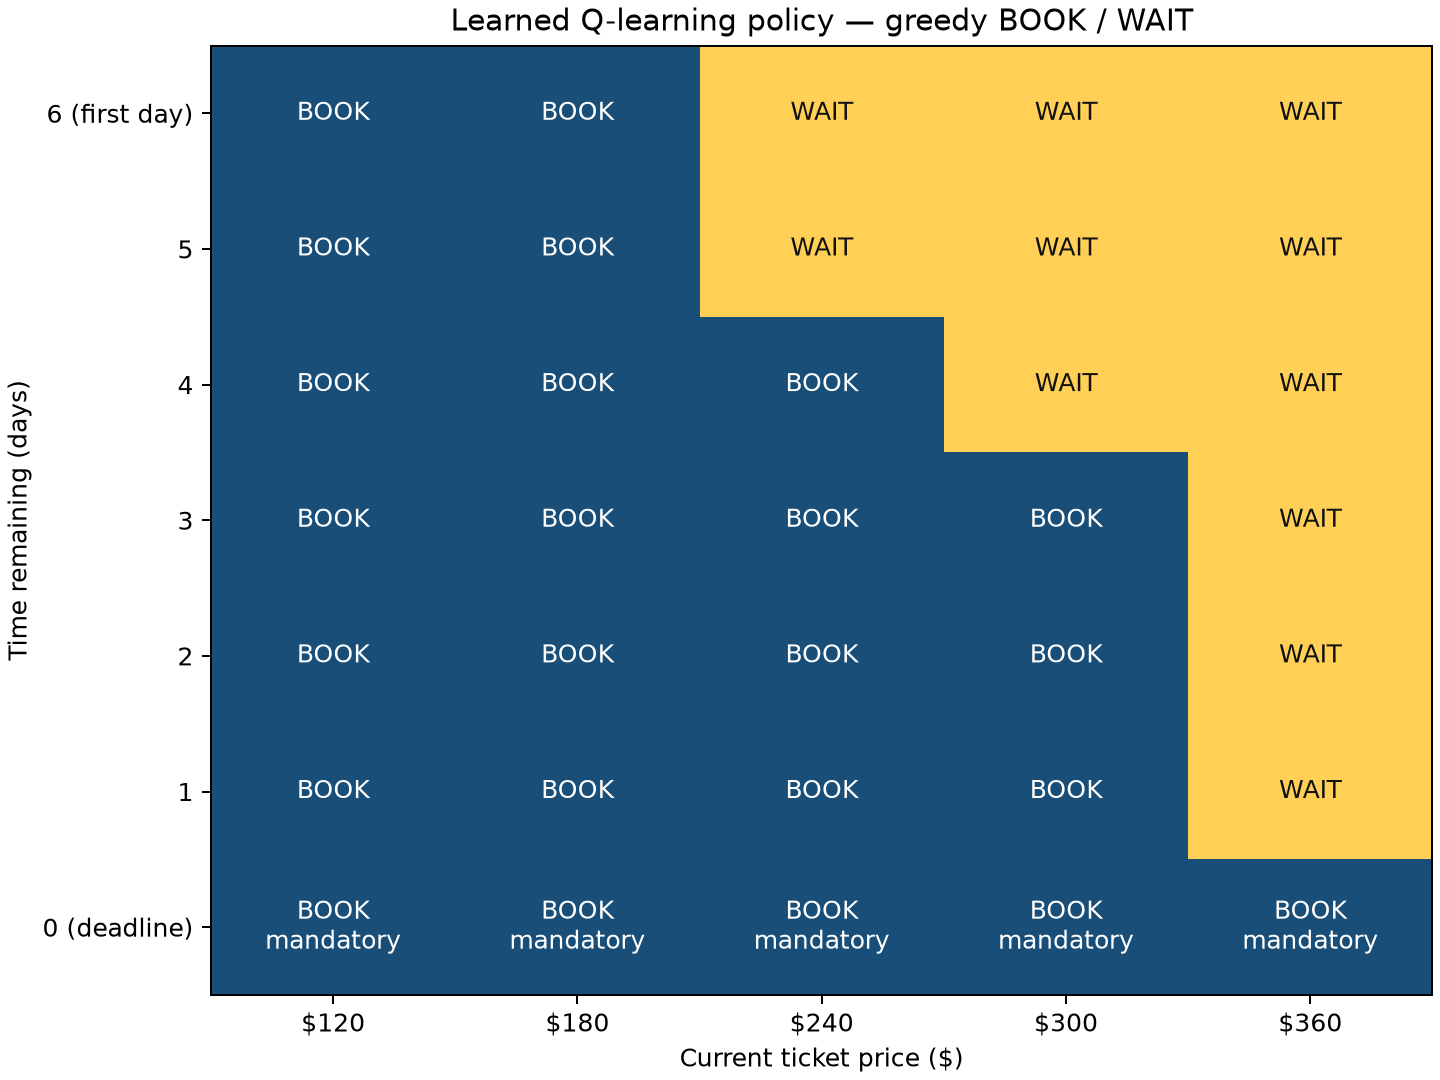

Saved policy_heatmap.png and all 35 policy actions; deadline BOOK verified.


In [21]:
# 7A — draw and save the learned policy heatmap
import os
os.environ.setdefault('MPLCONFIGDIR', str(Path('.cache/matplotlib').resolve()))
os.environ.setdefault('XDG_CACHE_HOME', str(Path('.cache').resolve()))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image
from matplotlib.colors import ListedColormap, BoundaryNorm

learned_actions = np.array([[best_action(Q, (t, int(price))) for price in PRICES]
                            for t in range(7)], dtype=int)
assert np.all(learned_actions[0] == BOOK)
assert np.array_equal(Q, q_before_evaluation)
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
cmap = ListedColormap(['#184e77', '#ffcf56'])
ax.imshow(learned_actions[::-1], cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5], 2), aspect='auto')
ax.set_xticks(range(5), [f'${price}' for price in PRICES])
ax.set_yticks(range(7), ['6 (first day)', '5', '4', '3', '2', '1', '0 (deadline)'])
ax.set_xlabel('Current ticket price ($)')
ax.set_ylabel('Time remaining (days)')
ax.set_title('Learned Q-learning policy — greedy BOOK / WAIT')
for row, t in enumerate(range(6, -1, -1)):
    for column in range(5):
        action = int(learned_actions[t, column])
        label = ACTION_NAMES[action] + ('\nmandatory' if t == 0 else '')
        ax.text(column, row, label, ha='center', va='center', fontsize=10,
                color='white' if action == BOOK else '#111111')
fig.savefig(RESULTS / 'policy_heatmap.png', dpi=180)
display(Image(filename=str(RESULTS / 'policy_heatmap.png')))
plt.close(fig)
save_csv('learned_policy_actions.csv', [{'time_remaining': t, 'price': int(price),
    'action': ACTION_NAMES[int(learned_actions[t, i])], 'mandatory': t == 0}
    for t in range(6, -1, -1) for i, price in enumerate(PRICES)])
print('Saved policy_heatmap.png and all 35 policy actions; deadline BOOK verified.')
verification_records.append({'check': 'policy actions', 'cases': 5, 'status': 'PASS', 'detail': 'all deadline prices force BOOK; Q-table unchanged'})


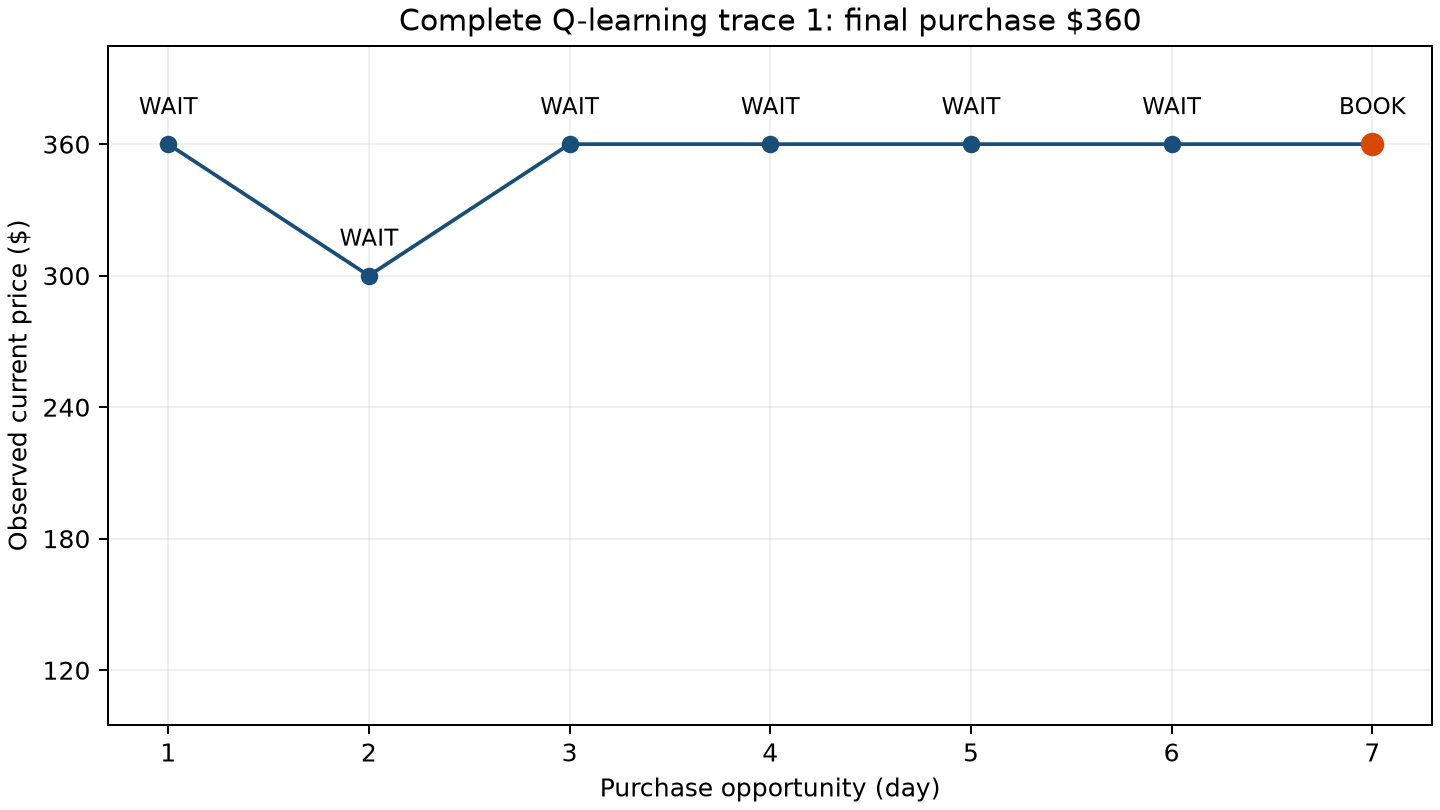

In [22]:
# 7B — save the complete observed trace as CSV and PNG
trace_rows = []
for step in decision_trace:
    t, price = step['state']
    book_value, wait_value = Q[t, PRICE_INDEX[price]]
    trace_rows.append({'trajectory_index': trace_index, 'day': step['day'],
        'time_remaining': t, 'price': price, 'action': step['action'],
        'reward': step['reward'], 'q_book': float(book_value),
        'q_wait': float(wait_value) if t > 0 else '',
        'purchase_cost': price if step['action'] == 'BOOK' else ''})
save_csv('q_learning_trace.csv', trace_rows)
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
days = [row['day'] for row in trace_rows]
prices_seen = [row['price'] for row in trace_rows]
ax.plot(days, prices_seen, color='#184e77', marker='o')
for day, price, row in zip(days, prices_seen, trace_rows):
    ax.annotate(row['action'], (day, price), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=9)
ax.scatter(days[-1], prices_seen[-1], color='#d94801', zorder=3, s=70)
ax.set_xticks(days)
ax.set_yticks(PRICES)
ax.set_ylim(95, 405)
ax.set_xlabel('Purchase opportunity (day)')
ax.set_ylabel('Observed current price ($)')
ax.set_title(f'Complete Q-learning trace {trace_index}: final purchase ${trace_cost}')
ax.grid(alpha=0.2)
fig.savefig(RESULTS / 'q_learning_trace.png', dpi=180)
display(Image(filename=str(RESULTS / 'q_learning_trace.png')))
plt.close(fig)

## 8. Paired 95% confidence intervals
**Purpose:** estimate uncertainty in the mean saving from this fixed learned policy. For each shared trajectory compute `d = baseline cost − Q-learning cost`; positive values favor Q-learning. Use the sample standard deviation of these paired differences, not separate unpaired cost variances.

Report the Student-t interval `mean(d) ± t(0.975, n−1) × sd(d)/√n`. With 10,000 independent trajectories this is a large-sample approximation for the mean of discrete differences. The three intervals are individual 95% intervals, not simultaneous family-wide intervals. They condition on the one trained policy and do not measure variability across training seeds, model misspecification, or savings on individual trips.

In [23]:
# 8A — paired Student-t interval and isolated checks
import scipy
from scipy.stats import t as student_t

def paired_interval(baseline_costs, learned_costs):
    baseline = np.asarray(baseline_costs, dtype=float)
    learned = np.asarray(learned_costs, dtype=float)
    if baseline.shape != learned.shape or baseline.ndim != 1 or len(baseline) < 2:
        raise ValueError('Need matching one-dimensional paired samples of length >= 2')
    differences = baseline - learned
    if not np.all(np.isfinite(differences)):
        raise ValueError('Costs must be finite')
    n = len(differences)
    mean = float(differences.mean())
    sd = float(differences.std(ddof=1))
    standard_error = sd / np.sqrt(n)
    critical_value = float(student_t.ppf(0.975, df=n - 1))
    half_width = critical_value * standard_error
    return {'trajectories': n, 'mean_paired_saving': mean, 'paired_sd': sd,
            'standard_error': float(standard_error), 'degrees_of_freedom': n - 1,
            'critical_value': critical_value, 'ci_95_lower': mean - half_width,
            'ci_95_upper': mean + half_width}

zero_check = paired_interval([120, 180, 240], [120, 180, 240])
assert zero_check['mean_paired_saving'] == zero_check['ci_95_lower'] == zero_check['ci_95_upper'] == 0
pair_check = paired_interval([120, 180, 240, 300], [120, 120, 180, 300])
assert pair_check['mean_paired_saving'] == 30
assert np.isclose(pair_check['paired_sd'], np.std([0, 60, 60, 0], ddof=1))
assert pair_check['degrees_of_freedom'] == 3
assert np.isclose(pair_check['critical_value'], 3.182446305, atol=1e-8)
print('PASS: paired differences, sample SD, Student-t critical value, and zero-difference interval.')
verification_records.append({'check': 'paired intervals', 'cases': 2, 'status': 'PASS', 'detail': 'zero differences; paired toy sample SD and Student-t critical value'})


PASS: paired differences, sample SD, Student-t critical value, and zero-difference interval.


In [24]:
# 8B — save all three paired savings intervals
savings_intervals = []
for name, costs in official_costs.items():
    if name != 'Q-learning (greedy)':
        record = {'baseline': name, **paired_interval(costs, q_costs)}
        assert np.isclose(record['mean_paired_saving'], costs.mean() - q_costs.mean())
        assert record['ci_95_lower'] <= record['mean_paired_saving'] <= record['ci_95_upper']
        savings_intervals.append(record)
assert len(savings_intervals) == 3
assert np.array_equal(Q, q_before_evaluation)
save_csv('paired_savings_95ci.csv', savings_intervals)
ci_table = '| Baseline | Mean Q-learning saving | Paired 95% CI |\n|---|---:|---:|\n'
for row in savings_intervals:
    ci_table += (f"| {row['baseline']} | ${row['mean_paired_saving']:.3f} | "
                 f"[${row['ci_95_lower']:.3f}, ${row['ci_95_upper']:.3f}] |\n")
display(Markdown(ci_table))
for row in savings_intervals:
    print(f"{row['baseline']}: saving ${row['mean_paired_saving']:.6f}; "
          f"95% CI [${row['ci_95_lower']:.6f}, ${row['ci_95_upper']:.6f}]")

| Baseline | Mean Q-learning saving | Paired 95% CI |
|---|---:|---:|
| Immediate booking | $24.726 | [$23.838, $25.614] |
| Minimum-price rule ($120) | $8.622 | [$7.241, $10.003] |
| Fixed-threshold rule ($180) | $4.884 | [$4.029, $5.739] |


Immediate booking: saving $24.726000; 95% CI [$23.837947, $25.614053]
Minimum-price rule ($120): saving $8.622000; 95% CI [$7.240777, $10.003223]
Fixed-threshold rule ($180): saving $4.884000; 95% CI [$4.029366, $5.738634]


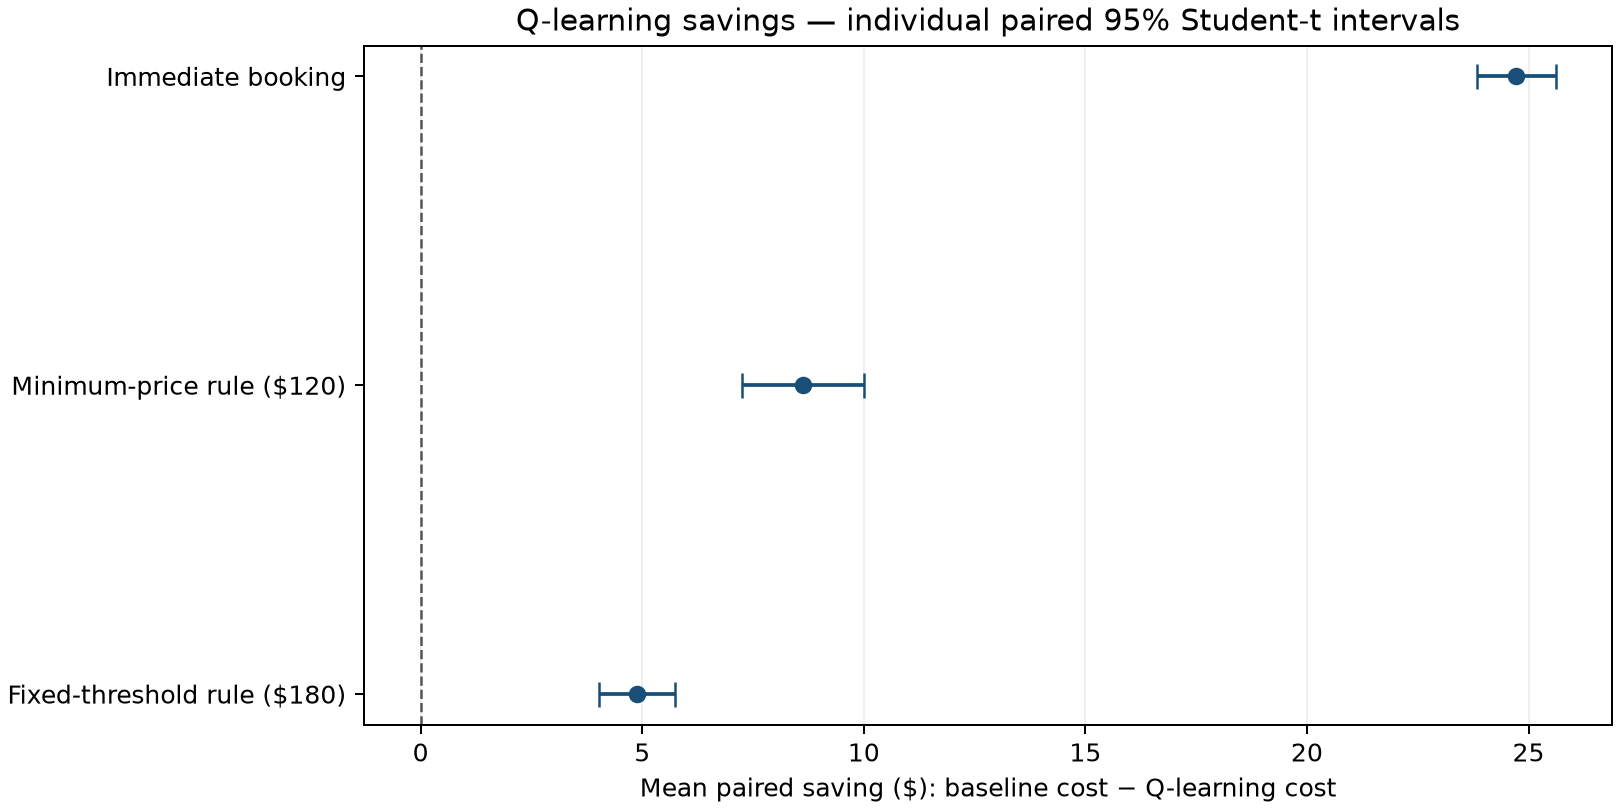

In [25]:
# 8C — save the paired confidence-interval figure
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
means = np.array([row['mean_paired_saving'] for row in savings_intervals])
lower = np.array([row['ci_95_lower'] for row in savings_intervals])
upper = np.array([row['ci_95_upper'] for row in savings_intervals])
ax.errorbar(means, np.arange(3), xerr=np.vstack([means - lower, upper - means]),
            fmt='o', capsize=5, color='#184e77')
ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
ax.set_yticks(range(3), [row['baseline'] for row in savings_intervals])
ax.invert_yaxis()
ax.set_xlabel('Mean paired saving ($): baseline cost − Q-learning cost')
ax.set_title('Q-learning savings — individual paired 95% Student-t intervals')
ax.grid(axis='x', alpha=0.2)
fig.savefig(RESULTS / 'paired_savings_95ci.png', dpi=180)
display(Image(filename=str(RESULTS / 'paired_savings_95ci.png')))
plt.close(fig)

## 9. Save actual results and verification evidence
**Purpose:** keep the mean comparison, all paired costs, test trajectories, learned Q-values, observed updates, and trace available for review. The executed Notebook itself stores the printed and displayed outputs. Rerunning writes fresh artifacts from that execution.

In [26]:
# 9A — final verification
# Future changes after purchase must never change decisions or cost.
future_checks = 0
for name, policy in OFFICIAL_POLICIES.items():
    for path in test_paths[:100]:
        cost, trace = play_path(path, policy)
        altered = path.copy()
        altered[len(trace):] = 120
        assert play_path(altered, policy) == (cost, trace)
        future_checks += 1
assert np.array_equal(Q, q_before_evaluation)
verification_records.append({'check': 'future-price isolation', 'cases': future_checks, 'status': 'PASS', 'detail': 'future suffix edits cannot change any observed decision; Q-table unchanged'})


In [27]:
# 9B — save paired costs and arrays
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
with (RESULTS / 'mean_cost_comparison.csv').open('w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=list(comparison[0]))
    writer.writeheader()
    writer.writerows(comparison)
with (RESULTS / 'paired_purchase_costs.csv').open('w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['trajectory_index', *OFFICIAL_POLICIES])
    for i in range(TEST_TRAJECTORIES):
        writer.writerow([i, *(official_costs[name][i] for name in OFFICIAL_POLICIES)])
np.save(RESULTS / 'test_trajectories.npy', test_paths)
np.save(RESULTS / 'q_values.npy', Q)
np.save(RESULTS / 'training_visit_counts.npy', visit_counts)
save_csv('verification_results.csv', verification_records)


In [28]:
# 9C — save actual run summary and trace
summary = {
    'training_seed': TRAIN_SEED, 'test_seed': TEST_SEED,
    'training_episodes': TRAIN_EPISODES, 'test_trajectories': TEST_TRAJECTORIES,
    'alpha': ALPHA, 'gamma': GAMMA, 'epsilon_start': 1.0, 'epsilon_end': 0.05,
    'epsilon_decay_episodes': 40_000, 'evaluation_exploration': 0,
    'official_threshold': OFFICIAL_THRESHOLD, 'comparison': comparison,
    'first_update': first_update, 'observed_wait_update': wait_update,
    'trace_index': trace_index, 'decision_trace': decision_trace,
    'final_purchase_cost': trace_cost,
    'verification': {'exact_transition_cases': transition_checks,
                     'purchase_days_checked': 7, 'legal_pairs_visited': int((legal_visits > 0).sum()),
                     'minimum_legal_pair_visits': int(legal_visits.min()),
                     'terminal_updates_reward_only': True, 'deadline_booking': True,
                     'post_purchase_rejected': True, 'q_unchanged_during_evaluation': True,
                     'future_suffix_invariance_cases': future_checks},
    'execution': {'python': sys.executable, 'python_version': sys.version.split()[0],
                  'numpy_version': np.__version__, 'scipy_version': scipy.__version__,
                  'matplotlib_version': matplotlib.__version__},
    'simulation_assumptions': assumptions, 'verification_results': verification_records,
    'exact_mdp': {'optimal_expected_cost': optimal_expected_cost,
                  'learned_policy_expected_cost': learned_expected_cost, 'gap_above_optimal': optimality_gap},
    'paired_95ci': savings_intervals, 'ci_method': 'individual paired Student-t; conditional on trained policy',
    'personally_practiced_by_user': 'Not established; user must run and explain the demo cells.'
}
(RESULTS / 'run_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
(RESULTS / 'official_comparison.md').write_text(table + '\nPositive paired saving = baseline cost minus Q-learning cost.\n')
(RESULTS / 'q_learning_trace.md').write_text(trace_table + f'\nTrajectory {trace_index}; final purchase cost: ${trace_cost}.\n')
print('PASS: 400 future-suffix invariance cases; all core checks passed.')
print('Saved actual comparison, 10,000 paired costs, price trajectories, Q-table, visits, updates, and complete trace in results/.')

PASS: 400 future-suffix invariance cases; all core checks passed.
Saved actual comparison, 10,000 paired costs, price trajectories, Q-table, visits, updates, and complete trace in results/.


## 10. Interpretation and limits
**Purpose:** explain actual observations without claiming convergence or universal savings. The following interpretation is calculated from the outputs of this execution.

In [29]:
# 10A — evidence-based interpretation
best_row = min(comparison, key=lambda row: row['mean_purchase_cost'])
fixed_saving = (official_costs['Fixed-threshold rule ($180)'] - q_costs).mean()
print(f"Lowest observed mean: {best_row['strategy']}, ${best_row['mean_purchase_cost']:.2f}.")
print(f"Mean paired saving from Q-learning versus the official $180 rule: ${fixed_saving:.3f}.")
print(f"The displayed Q-learning trajectory still costs ${trace_cost}; average savings do not imply savings on every trip.")
print('These results cover one training seed and one test sample from hypothetical probabilities.')
print('Fixed learning rate and finite training do not guarantee convergence. No real-flight recommendation is supported.')
print(f'Analytical optimum: ${optimal_expected_cost:.6f}; learned policy: ${learned_expected_cost:.6f}; gap: ${optimality_gap:.6f}.')
print('Individual paired intervals quantify test-sample uncertainty conditional on this trained policy.')

Lowest observed mean: Q-learning (greedy), $214.85.
Mean paired saving from Q-learning versus the official $180 rule: $4.884.
The displayed Q-learning trajectory still costs $360; average savings do not imply savings on every trip.
These results cover one training seed and one test sample from hypothetical probabilities.
Fixed learning rate and finite training do not guarantee convergence. No real-flight recommendation is supported.
Analytical optimum: $207.274224; learned policy: $215.709120; gap: $8.434896.
Individual paired intervals quantify test-sample uncertainty conditional on this trained policy.


In [30]:
# 10B — write the findings and linked evidence from this execution
report = f"""# Actual results — Flight Booking Decision Assistant

This report is generated from the executed [main Notebook](CS664_Flight_Booking.ipynb).
The instructor PDF supplies the official rubric; the unchanged proposal is the implementation plan.

## Simulation and training
Seven opportunities (time 6 to 0); fares $120/$180/$240/$300/$360; uniform initial fare.
WAIT changes fare by +$60/$0/−$60 with probabilities 30%/30%/40% at times 6–3,
and 60%/20%/20% at times 2–1. Boundary moves stay at $120 or $360.
BOOK rewards negative fare and terminates; WAIT rewards 0; deadline BOOK is mandatory.
These are hypothetical assumptions; there are no refunds, cancellations, or sold-out events.
Training: {TRAIN_EPISODES:,} episodes, alpha {ALPHA}, gamma {GAMMA}, seed {TRAIN_SEED};
epsilon 1.0 to 0.05 over 40,000 episodes, then 0.05. Test seed: {TEST_SEED}.
See [assumptions](results/simulation_assumptions.json), [parameters CSV](results/training_parameters.csv),
and [run summary](results/run_summary.json).

## Sampled evaluation — 10,000 shared fresh trajectories
Every policy receives only current state. Q-learning evaluation is greedy with no updates.
{table}
{ci_table}
[Mean-cost CSV](results/mean_cost_comparison.csv) · [paired savings/CI CSV](results/paired_savings_95ci.csv) ·
[10,000 paired costs](results/paired_purchase_costs.csv) · [CI figure](results/paired_savings_95ci.png).
Positive saving means baseline cost minus learned-policy cost. Lowest sampled mean:
{best_row['strategy']} (${best_row['mean_purchase_cost']:.3f}). These are sampled results, not analytical expectations.

## Analytical finite-horizon reference — full model expectation
Optimal expected cost: **${optimal_expected_cost:.6f}**.
Learned-policy expected cost: **${learned_expected_cost:.6f}**.
Learned policy minus optimum: **${optimality_gap:.6f}**.
Values average uniformly over the five initial fares and use full backward induction;
“exact” means analytical expectation to floating-point precision. The trained policy is suboptimal.
[Exact comparison CSV](results/exact_mdp_comparison.csv) · [per-state values CSV](results/exact_state_values.csv).
These reference probabilities are never supplied to the learning agent or used to tune its policy.

## Policy, trace, and verification
[BOOK/WAIT heatmap](results/policy_heatmap.png) · [policy actions CSV](results/learned_policy_actions.csv).
[Complete trace CSV](results/q_learning_trace.csv) · [trace figure](results/q_learning_trace.png) ·
[trace table](results/q_learning_trace.md). Illustrated trajectory {trace_index} ends at ${trace_cost};
it was selected as the first example with at least three decisions, not to estimate performance.
[Verification CSV](results/verification_results.csv) records actually executed checks:
90 transitions, all seven purchase days, rewards, deadline booking, termination,
Q updates, 400 future-suffix checks, and independent 3,645-path expectations for five reference policies.

## Limitations and remaining submission work
Individual paired 95% Student-t intervals are large-sample approximations conditional on this trained policy;
they are not simultaneous intervals and do not quantify training-seed variation or real-flight uncertainty.
The test trajectories are independent; cost differences retain within-trajectory pairing.
Fixed-rate finite training does not guarantee convergence. Average savings do not guarantee savings on each trip.
Practice is paused and the separate practice Notebook is unchanged. Agent execution is not personal practice.
Still required: final PDF/Word proposal/writeup, project zip with README, and an approximately
10-minute camera-on presentation with code explanation and a full demo, per the instructor PDF.
"""
Path('RESULTS.md').write_text(report)
display(Markdown('Saved [RESULTS.md](RESULTS.md) with findings and links to actual evidence.'))

Saved [RESULTS.md](RESULTS.md) with findings and links to actual evidence.

## 11. Essential cells to personally run and explain before recording
The implementation agent wrote and executed the core, including the default practice example. **Your personal practice has not been observed or recorded.** Before making the approximately 10-minute video required by the assignment, select the project kernel and restart/run the entire Notebook yourself.

Use these labeled cells as your explanation checklist:

1. **1A:** show the interpreter, independent seeds, α = 0.1, γ = 1, 50,000 training episodes, and 10,000 test paths.
2. **2A–2D:** explain the two probability regimes, boundary stays, negative purchase reward, zero WAIT reward, seven opportunities, mandatory deadline booking, and termination checks.
3. **3A–3D:** explain state indexing, epsilon-greedy training versus greedy predictions, terminal versus nonterminal targets, and the actual old/target/learning-rate/updated Q-values.
4. **4A–4E:** explain why every strategy gets the same trajectories, how state-only calls prevent future access, why testing has no exploration, and how mean paired saving is calculated.
5. **5A:** narrate the complete trace until purchase, including the final cost and why a single trip may be expensive.
6. Guided practice is paused. The separate practice Notebook is unchanged; complete personal exercises afterward. The optional appendix preserves the original threshold demonstration.
7. **6A–6D, 7A–7B, 8A–8C, 9A–9C, and 10A:** show the saved evidence, explain observed results and limits, and distinguish analytical expectations from sampled results and confidence intervals.

The unchanged proposal and course PDF remain in the project folder. This core Notebook and README do not replace the separate final PDF/Word proposal/writeup or your camera-on recording required by the assignment.

## Appendix. Optional threshold demonstration
**Purpose:** practice how a simple rule affects cost. Change only `PRACTICE_THRESHOLD` in 6A to 120, 180, 240, 300, or 360, then rerun 6A. It reuses the test trajectories for exploration of the model; it is not a new held-out evaluation. Never choose or tune the official threshold from these results.

The official four-strategy costs and threshold remain intact. Guided practice is paused; use the separate unchanged practice Notebook later. This demonstration was executed by the implementation agent; it does **not** establish that you personally practiced it.

In [31]:
# 6A — editable practice threshold (official comparison unchanged)
PRACTICE_THRESHOLD = 240  # CHANGE THIS VALUE, then rerun this cell.
if PRACTICE_THRESHOLD not in PRICE_INDEX:
    raise ValueError("Choose 120, 180, 240, 300, or 360")
official_snapshot = {name: costs.copy() for name, costs in official_costs.items()}
practice_costs = np.array([play_path(path, threshold_policy(PRACTICE_THRESHOLD))[0]
                          for path in test_paths])
print(f"PRACTICE ONLY: threshold ${PRACTICE_THRESHOLD}; mean cost ${practice_costs.mean():.2f}")
print(f"Official threshold remains ${OFFICIAL_THRESHOLD}; official mean is ${official_costs['Fixed-threshold rule ($180)'].mean():.2f}")
assert OFFICIAL_THRESHOLD == 180
assert all(np.array_equal(official_costs[name], costs) for name, costs in official_snapshot.items())

PRACTICE ONLY: threshold $240; mean cost $219.86
Official threshold remains $180; official mean is $219.74
